# Continuous XNOR — feature-only learnability

Before interpreting preference, test whether each rule can be learned separately. Both models use width 32, full-batch SGD, learning rate 0.03, and 500 updates across five seeds. The complex-only model receives two coordinates; the simple-only model receives one. Parameter counts are therefore not matched.

Run top to bottom. Live plots show the current model. Final cells compare every run. Set `QUICK_RUN=True` only for a preview; preview output is kept separate.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import json
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, clear_output, Code

# Launch Jupyter here, or open these notebooks from the project root.
HERE = Path.cwd()
if not (HERE / 'notebook_experiment.py').exists():
    HERE = HERE / 'continuous_xnor'
assert (HERE / 'notebook_experiment.py').exists(), 'Launch Jupyter from the continuous_xnor folder.'
sys.path.insert(0, str(HERE))
from notebook_experiment import *
torch.set_num_threads(1)
RESULTS = HERE / 'results'
print('PyTorch:', torch.__version__)


PyTorch: 2.14.1+cpu


In [2]:
# Default research settings. Preview results go into a separate folder.
QUICK_RUN = False
SHOW_LIVE = True
SEEDS = [42, 43, 44, 45, 46]
STEPS = 500
LR = 0.03
if QUICK_RUN:
    SEEDS = [42]
    STEPS = 25
    RESULTS = RESULTS / 'preview'
splits = make_splits()
train_data = splits['train']
validation_data = splits['validation']
test_data = splits['test']
print('Updates:', STEPS, '| seeds:', SEEDS, '| output:', RESULTS)


Updates: 500 | seeds: [42, 43, 44, 45, 46] | output: c:\Users\ESHAAN\HAKUR\SimpBias\continuous_xnor\results


## The training loop

Only training labels enter the loss used by backpropagation. Validation loss and accuracy are recorded every 25 updates. There is no early stopping. The optional `on_log` function updates the live plot; it does not affect optimization.

In [4]:
def show_training(history, title):
    # Redraw every 100 updates and at the end, rather than creating hundreds
    # of figures for every model. All checkpoints are still recorded every 25.
    step = history[-1]['step']
    if step % 100 != 0 and step != STEPS:
        return
    frame = pd.DataFrame(history)
    clear_output(wait=True)
    has_conflicts = 'complex_conflict_agreement' in frame
    fig, axes = plt.subplots(1, 3 if has_conflicts else 2, figsize=(13, 3.3))
    for split in ['train', 'validation']:
        axes[0].plot(frame.step, frame[f'{split}_loss'], label=split)
        axes[1].plot(frame.step, frame[f'{split}_accuracy'], label=split)
    axes[0].set(title='BCE loss', xlabel='SGD step')
    axes[1].set(title='Accuracy', xlabel='SGD step', ylim=(-0.05, 1.05))
    if has_conflicts:
        axes[2].plot(frame.step, frame.complex_conflict_agreement, label='complex rule')
        axes[2].set(title='Conflict agreement', xlabel='SGD step', ylim=(-0.05, 1.05))
    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend()
    fig.suptitle(f'{title} | step {step}/{STEPS}')
    fig.tight_layout()
    display(fig)
    plt.close(fig)
    print('Current validation accuracy:', round(history[-1]['validation_accuracy'], 4))


## Train the two feature-only models

For each seed, use the same data and optimizer budget. Test data are evaluated only after that model's training finishes. A short preview is a software check, not evidence of successful learnability.

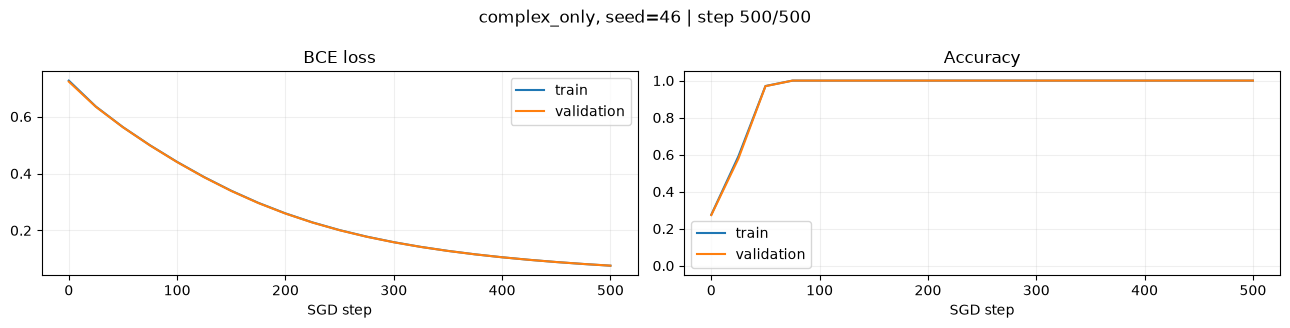

Current validation accuracy: 1.0
Saved baseline outputs to c:\Users\ESHAAN\HAKUR\SimpBias\continuous_xnor\results


In [5]:
baseline_rows, baseline_history = [], []
for seed in SEEDS:
    for name, columns in [('simple_only', [0]), ('complex_only', [1, 2])]:
        model = make_model(seed, inputs=len(columns))
        training = (train_data[0][:, columns], train_data[1])
        validation = (validation_data[0][:, columns], validation_data[1])
        title = f'{name}, seed={seed}'
        callback = (lambda history: show_training(history, title)) if SHOW_LIVE else None
        history = train_model(model, training, validation, steps=STEPS, lr=LR, on_log=callback)
        info = {'condition': name, 'seed': seed, 'alpha': 1.0}
        baseline_history.extend({**info, **row} for row in history)
        final = {**info, **history[-1]}
        testing = (test_data[0][:, columns], test_data[1])
        final.update({f'test_{k}': v for k, v in classification_metrics(model, testing).items()})
        baseline_rows.append(final)
        if not SHOW_LIVE:
            print(title, '| test accuracy:', round(final['test_accuracy'], 4))
save_rows(RESULTS / 'baseline_summary.csv', baseline_rows)
save_rows(RESULTS / 'baseline_history.csv', baseline_history)
save_json(RESULTS / 'baseline_settings.json', {'seeds': SEEDS, 'steps': STEPS, 'lr': LR, 'alpha': 1.0})
print('Saved baseline outputs to', RESULTS)


## Inspect every seed and compare learning curves

High held-out accuracy in both models supports separate learnability under this budget. Failure of the complex-only model weakens an interpretation of joint simple preference as choosing between two readily learnable options. Equal final accuracy does not imply equal convergence speed or confidence.

,condition,seed,alpha,step,train_loss,train_accuracy,validation_loss,validation_accuracy,test_loss,test_accuracy
0,simple_only,42,1.0,500,0.015136,1.0,0.014502,1.0,0.014773,1.0
1,complex_only,42,1.0,500,0.086577,1.0,0.088596,1.0,0.087668,1.0
2,simple_only,43,1.0,500,0.016237,1.0,0.015634,1.0,0.015896,1.0
3,complex_only,43,1.0,500,0.103667,1.0,0.106436,1.0,0.105405,1.0
4,simple_only,44,1.0,500,0.015693,1.0,0.015093,1.0,0.015350,1.0
5,complex_only,44,1.0,500,0.091313,1.0,0.092211,1.0,0.092222,1.0
6,simple_only,45,1.0,500,0.014620,1.0,0.014159,1.0,0.014380,1.0
7,complex_only,45,1.0,500,0.082411,1.0,0.083221,1.0,0.084098,1.0
8,simple_only,46,1.0,500,0.015226,1.0,0.014630,1.0,0.014894,1.0
9,complex_only,46,1.0,500,0.076040,1.0,0.076098,1.0,0.076946,1.0


test_accuracy      test_loss          
                      mean  std      mean       std
condition                                          
complex_only           1.0  0.0  0.089268  0.010610
simple_only            1.0  0.0  0.015058  0.000582

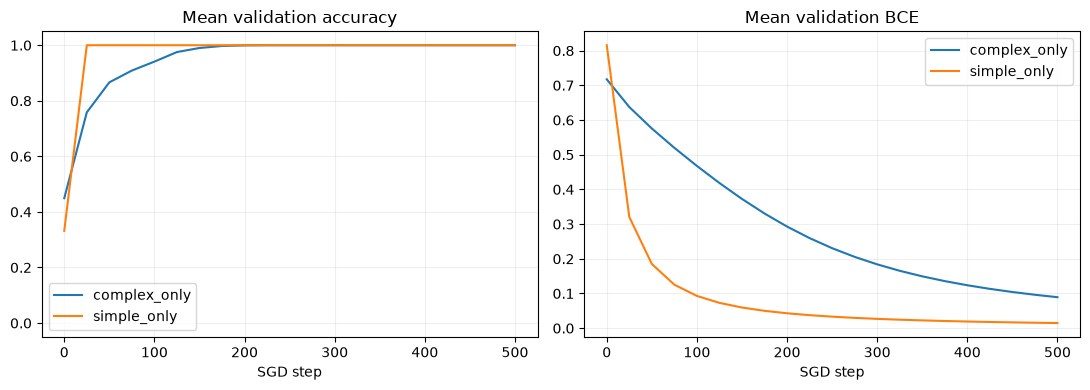

In [8]:
baseline = pd.DataFrame(baseline_rows)
curves = pd.DataFrame(baseline_history)
display(baseline)
display(baseline.groupby('condition')[['test_accuracy', 'test_loss']].agg(['mean', 'std']))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for condition, group in curves.groupby('condition'):
    mean = group.groupby('step')[['validation_accuracy', 'validation_loss']].mean()
    axes[0].plot(mean.index, mean.validation_accuracy, label=condition)
    axes[1].plot(mean.index, mean.validation_loss, label=condition)
axes[0].set(title='Mean validation accuracy', xlabel='SGD step', ylim=(-0.05, 1.05))
axes[1].set(title='Mean validation BCE', xlabel='SGD step')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
